In [1]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Hit:1 https://cli.github.com/packages stable InRelease
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:3 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Get:5 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:6 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:8 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Hit:9 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Get:10 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,054 kB]
Get:11 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,546 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:13 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/mai

In [2]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Writing main.cpp


In [3]:
!g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [4]:
%%writefile setup.sh
#!/bin/bash
echo "[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor..."
apt-get update -qq && apt-get install -y -qq libopencv-dev build-essential cmake > /dev/null

echo "[2/3] C++ uygulaması derleniyor..."
g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart

echo "[3/3] Uygulama çalıştırılıyor..."
./app

Writing setup.sh


In [5]:
!bash setup.sh

[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
[2/3] C++ uygulaması derleniyor...
[3/3] Uygulama çalıştırılıyor...
OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
# !cp /content/drive/MyDrive/Colab_CPP_OpenCV/* /content/
# !bash setup.sh

Prewitt Calisma Suresi : 5.753 ms
Sobel Calisma Suresi   : 7.481 ms
Canny Calisma Suresi   : 12.515 ms


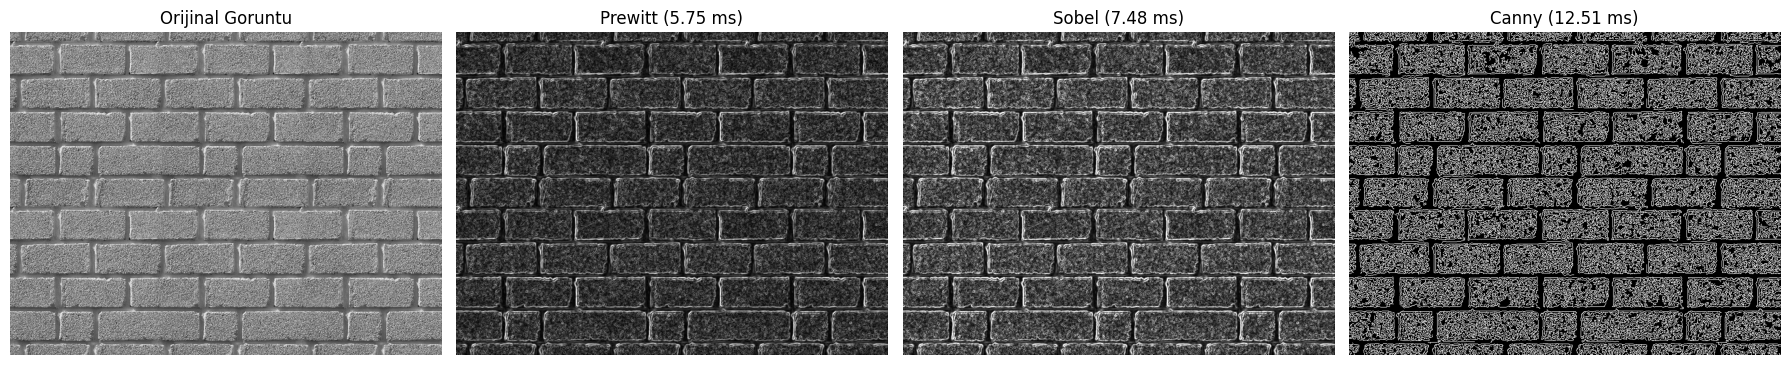

In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

# 1. Görüntüyü gri tonlamalı oku
# Dosya adını 'images_1.jpeg' veya 'images_2.jpeg' olarak belirleyebilirsiniz
img = cv2.imread('images_1.jpeg', cv2.IMREAD_GRAYSCALE)

# Ortak ön işleme: Gürültüyü azaltmak için Gauss filtresi
blurred = cv2.GaussianBlur(img, (3, 3), 1.0)

# ==========================================
# 1. CANNY KENAR TESPİTİ
# ==========================================
start_canny = time.perf_counter()
# Alt eşik: 50, Üst eşik: 150 (Histerezis eşikleme)
canny_edges = cv2.Canny(blurred, 50, 150)
time_canny = (time.perf_counter() - start_canny) * 1000  # ms cinsinden

# ==========================================
# 2. SOBEL OPERATÖRÜ
# ==========================================
start_sobel = time.perf_counter()
sobel_x = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_magnitude = cv2.magnitude(sobel_x, sobel_y)
sobel_edges = np.uint8(np.clip(sobel_magnitude, 0, 255))
time_sobel = (time.perf_counter() - start_sobel) * 1000

# ==========================================
# 3. PREWITT OPERATÖRÜ
# ==========================================
start_prewitt = time.perf_counter()
kernel_px = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)
kernel_py = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float32)
prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_px)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_py)
prewitt_magnitude = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_edges = np.uint8(np.clip(prewitt_magnitude, 0, 255))
time_prewitt = (time.perf_counter() - start_prewitt) * 1000

# ==========================================
# ÇALIŞMA SÜRELERİNİ YAZDIRMA
# ==========================================
print(f"Prewitt Calisma Suresi : {time_prewitt:.3f} ms")
print(f"Sobel Calisma Suresi   : {time_sobel:.3f} ms")
print(f"Canny Calisma Suresi   : {time_canny:.3f} ms")

# ==========================================
# GÖRSELLEŞTİRME
# ==========================================
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(img, cmap='gray')
axes[0].set_title('Orijinal Goruntu')
axes[0].axis('off')

axes[1].imshow(prewitt_edges, cmap='gray')
axes[1].set_title(f'Prewitt ({time_prewitt:.2f} ms)')
axes[1].axis('off')

axes[2].imshow(sobel_edges, cmap='gray')
axes[2].set_title(f'Sobel ({time_sobel:.2f} ms)')
axes[2].axis('off')

axes[3].imshow(canny_edges, cmap='gray')
axes[3].set_title(f'Canny ({time_canny:.2f} ms)')
axes[3].axis('off')

plt.tight_layout()
plt.show()